# Relationship Between Fitbit Usage and Daily Steps

To understand the relationship between user engagement and physical activity, the average daily steps for each user were calculated and combined with their total activity usage days. The correlation between these two metrics was then examined to determine whether users who recorded activity more consistently tended to have higher average daily step counts.

### 1. Loading Libraries and Datasets

Import the required Python libraries and load the daily activity and total usage datasets. Pandas is used for data manipulation, Seaborn for statistical visualization, and Matplotlib for customizing the chart.

In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Loading data
df = pd.read_csv("dailyActivity_merged.csv")
df_total_usage = pd.read_csv("total_usage.csv") # from Analysis_2_Fitbit_usage



### 2. Cleaning the Daily Activity Data

Convert the `ActivityDate` column to a datetime format to support consistent date handling and future analysis. Then, create a copy of the original dataset and remove duplicate rows to ensure data quality.

The original and cleaned row counts are compared to identify how many duplicate records were removed.

In [9]:
# Cleaning data
df['ActivityDate'] = pd.to_datetime(
    df['ActivityDate'],
    format='%m/%d/%Y'
)

In [2]:
df_original = df.copy()

df = df.drop_duplicates()

print('Original:', len(df_original))
print('Cleaned:', len(df))
print('Rows dropped:', len(df_original) - len(df))

Original: 457
Cleaned: 457
Rows dropped: 0


### 3. Renaming Column Names

Rename the original column names from PascalCase to snake_case to improve readability and maintain consistent naming conventions throughout the analysis.

For example, `Id` becomes `user_id`, `TotalSteps` becomes `total_steps`, and `ActivityDate` becomes `activity_date`. This makes the column names easier to reference in subsequent data manipulation and analysis.

In [3]:
# Renaming column names from PascalCase to snake_case
df = df.rename(columns={
    'Id': 'user_id',
    'ActivityDate': 'activity_date',
    'TotalSteps': 'total_steps',
    'TotalDistance': 'total_distance',
    'TrackerDistance': 'tracker_distance',
    'LoggedActivitiesDistance': 'logged_activities_distance',
    'VeryActiveDistance': 'very_active_distance',
    'ModeratelyActiveDistance': 'moderately_active_distance',
    'LightActiveDistance': 'light_active_distance',
    'SedentaryActiveDistance': 'sedentary_active_distance',
    'VeryActiveMinutes': 'very_active_minutes',
    'FairlyActiveMinutes': 'fairly_active_minutes',
    'LightlyActiveMinutes': 'lightly_active_minutes',
    'SedentaryMinutes': 'sedentary_minutes',
    'Calories': 'calories'
})

### 4. Calculating Average Daily Steps per User

Group the daily activity data by `user_id` and calculate the mean of `total_steps` for each user.

The resulting dataset contains one row per user, with `avg_daily_steps` representing their average daily step count across the recorded activity days. This metric will be used to examine the relationship between activity tracking consistency and daily physical activity.

In [ ]:
# Calculate average daily steps per user
df_avg_steps = (
    df.groupby('user_id', as_index=False)
    .agg(avg_daily_steps=('total_steps', 'mean'))
)

df_avg_steps

### 5. Merging Average Daily Steps and Usage Data

Merge the average daily steps dataset with the total usage dataset using `user_id` as the common key.

An inner join retains only users present in both datasets, while `validate='one_to_one'` checks that each user appears at most once in each dataset. This ensures that the merged data is structured correctly for the correlation analysis.

In [ ]:
df_merged_avg_steps = pd.merge(
    df_avg_steps,
    df_total_usage,
    on='user_id',
    how='inner',
    validate='one_to_one'
)


np.float64(0.407029402404137)

### 6. Calculating the Correlation

Calculate the Pearson correlation coefficient between `avg_daily_steps` and `total_usage_days` to assess the direction and strength of their linear relationship.

The coefficient ranges from -1 to +1. A positive value indicates that higher usage-day counts tend to be associated with higher average daily steps, while a value near zero indicates a weaker linear relationship.

In [10]:
correlation = df_merged_avg_steps[
    'avg_daily_steps'
].corr(
    df_merged_avg_steps['total_usage_days']
)

correlation

np.float64(0.407029402404137)

### 7. Visualizing Fitbit Usage Days vs. Average Daily Steps

Create a scatter plot with a regression line to visualize the relationship between `total_usage_days` and `avg_daily_steps`.

- **X-axis:** Total number of days a user recorded activity.
- **Y-axis:** Average daily steps per user.
- **Scatter points:** Individual users.
- **Regression line:** The overall linear trend between the two variables.

The scatter plot helps identify whether users with more consistent activity tracking tend to record higher average daily step counts. The visualization complements the correlation coefficient by showing the distribution and variability of individual users' data.

Text(0, 0.5, 'Average Daily Steps')

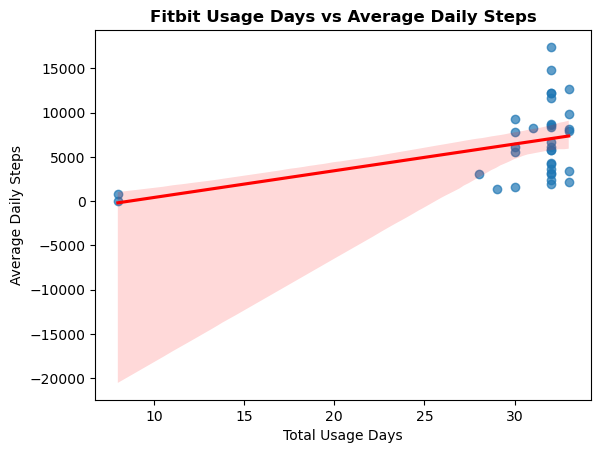

In [7]:
sns.regplot(
    data=df_merged_avg_steps,
    x='total_usage_days',
    y='avg_daily_steps',
    scatter_kws={'alpha': 0.7},
    line_kws={'color': 'red'}
)

plt.title(
    'Fitbit Usage Days vs Average Daily Steps',
    fontweight='bold'
)
plt.xlabel('Total Usage Days')
plt.ylabel('Average Daily Steps')

### Key Finding

The analysis reveals a moderate positive correlation (\(r = 0.407\)) between total activity usage days and average daily steps.

Users with more recorded activity days tend to have higher average daily step counts. However, the relationship varies across individuals, indicating that tracking consistency alone does not fully explain differences in daily physical activity.

**Business implication:** Bellabeat could explore engagement strategies that encourage users to track their activity consistently while providing personalized daily movement goals. Further analysis would be needed to determine whether these strategies improve physical activity levels.